In [173]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
from qiskit_experiments.framework import ExperimentData
from qiskit_experiments.library import StandardRB
from qiskit_experiments.framework import BatchExperiment
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration of APL pi pulses on two qubits

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [5]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 128 # dt, apl pulses
desired_duration = 120 # dt, new pulses

granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

In [6]:
# pico_a = ps.from_csv(
#     "../pico-pulses/apl-pulses/x_gates.csv" # gates with 2 pi offset
# )
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-06-27/single_qubit_gateset.csv" # gates without 2 pi offset
)
pico_gates = {key: row for key, row in zip(["x1", "i1", "x2", "i2"], pico_a)}

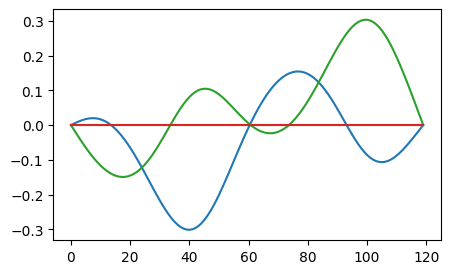

In [7]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

In [8]:
np.trapz(pico_gates["x1"], dx=dt), np.trapz(pico_gates["x2"], dx=dt)

(-3.1373487889817544, 3.137413414080159)

In [9]:
default_gates = {
    "x1": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples),
    "x2": np.real(ps.gaussian_envelope(duration, dt=dt, angle=np.pi).samples)
}

In [10]:
np.trapz(default_gates["x1"], dx=dt), np.trapz(default_gates["x2"], dx=dt)

(3.141507075143458, 3.141507075143458)

# Qubits to use

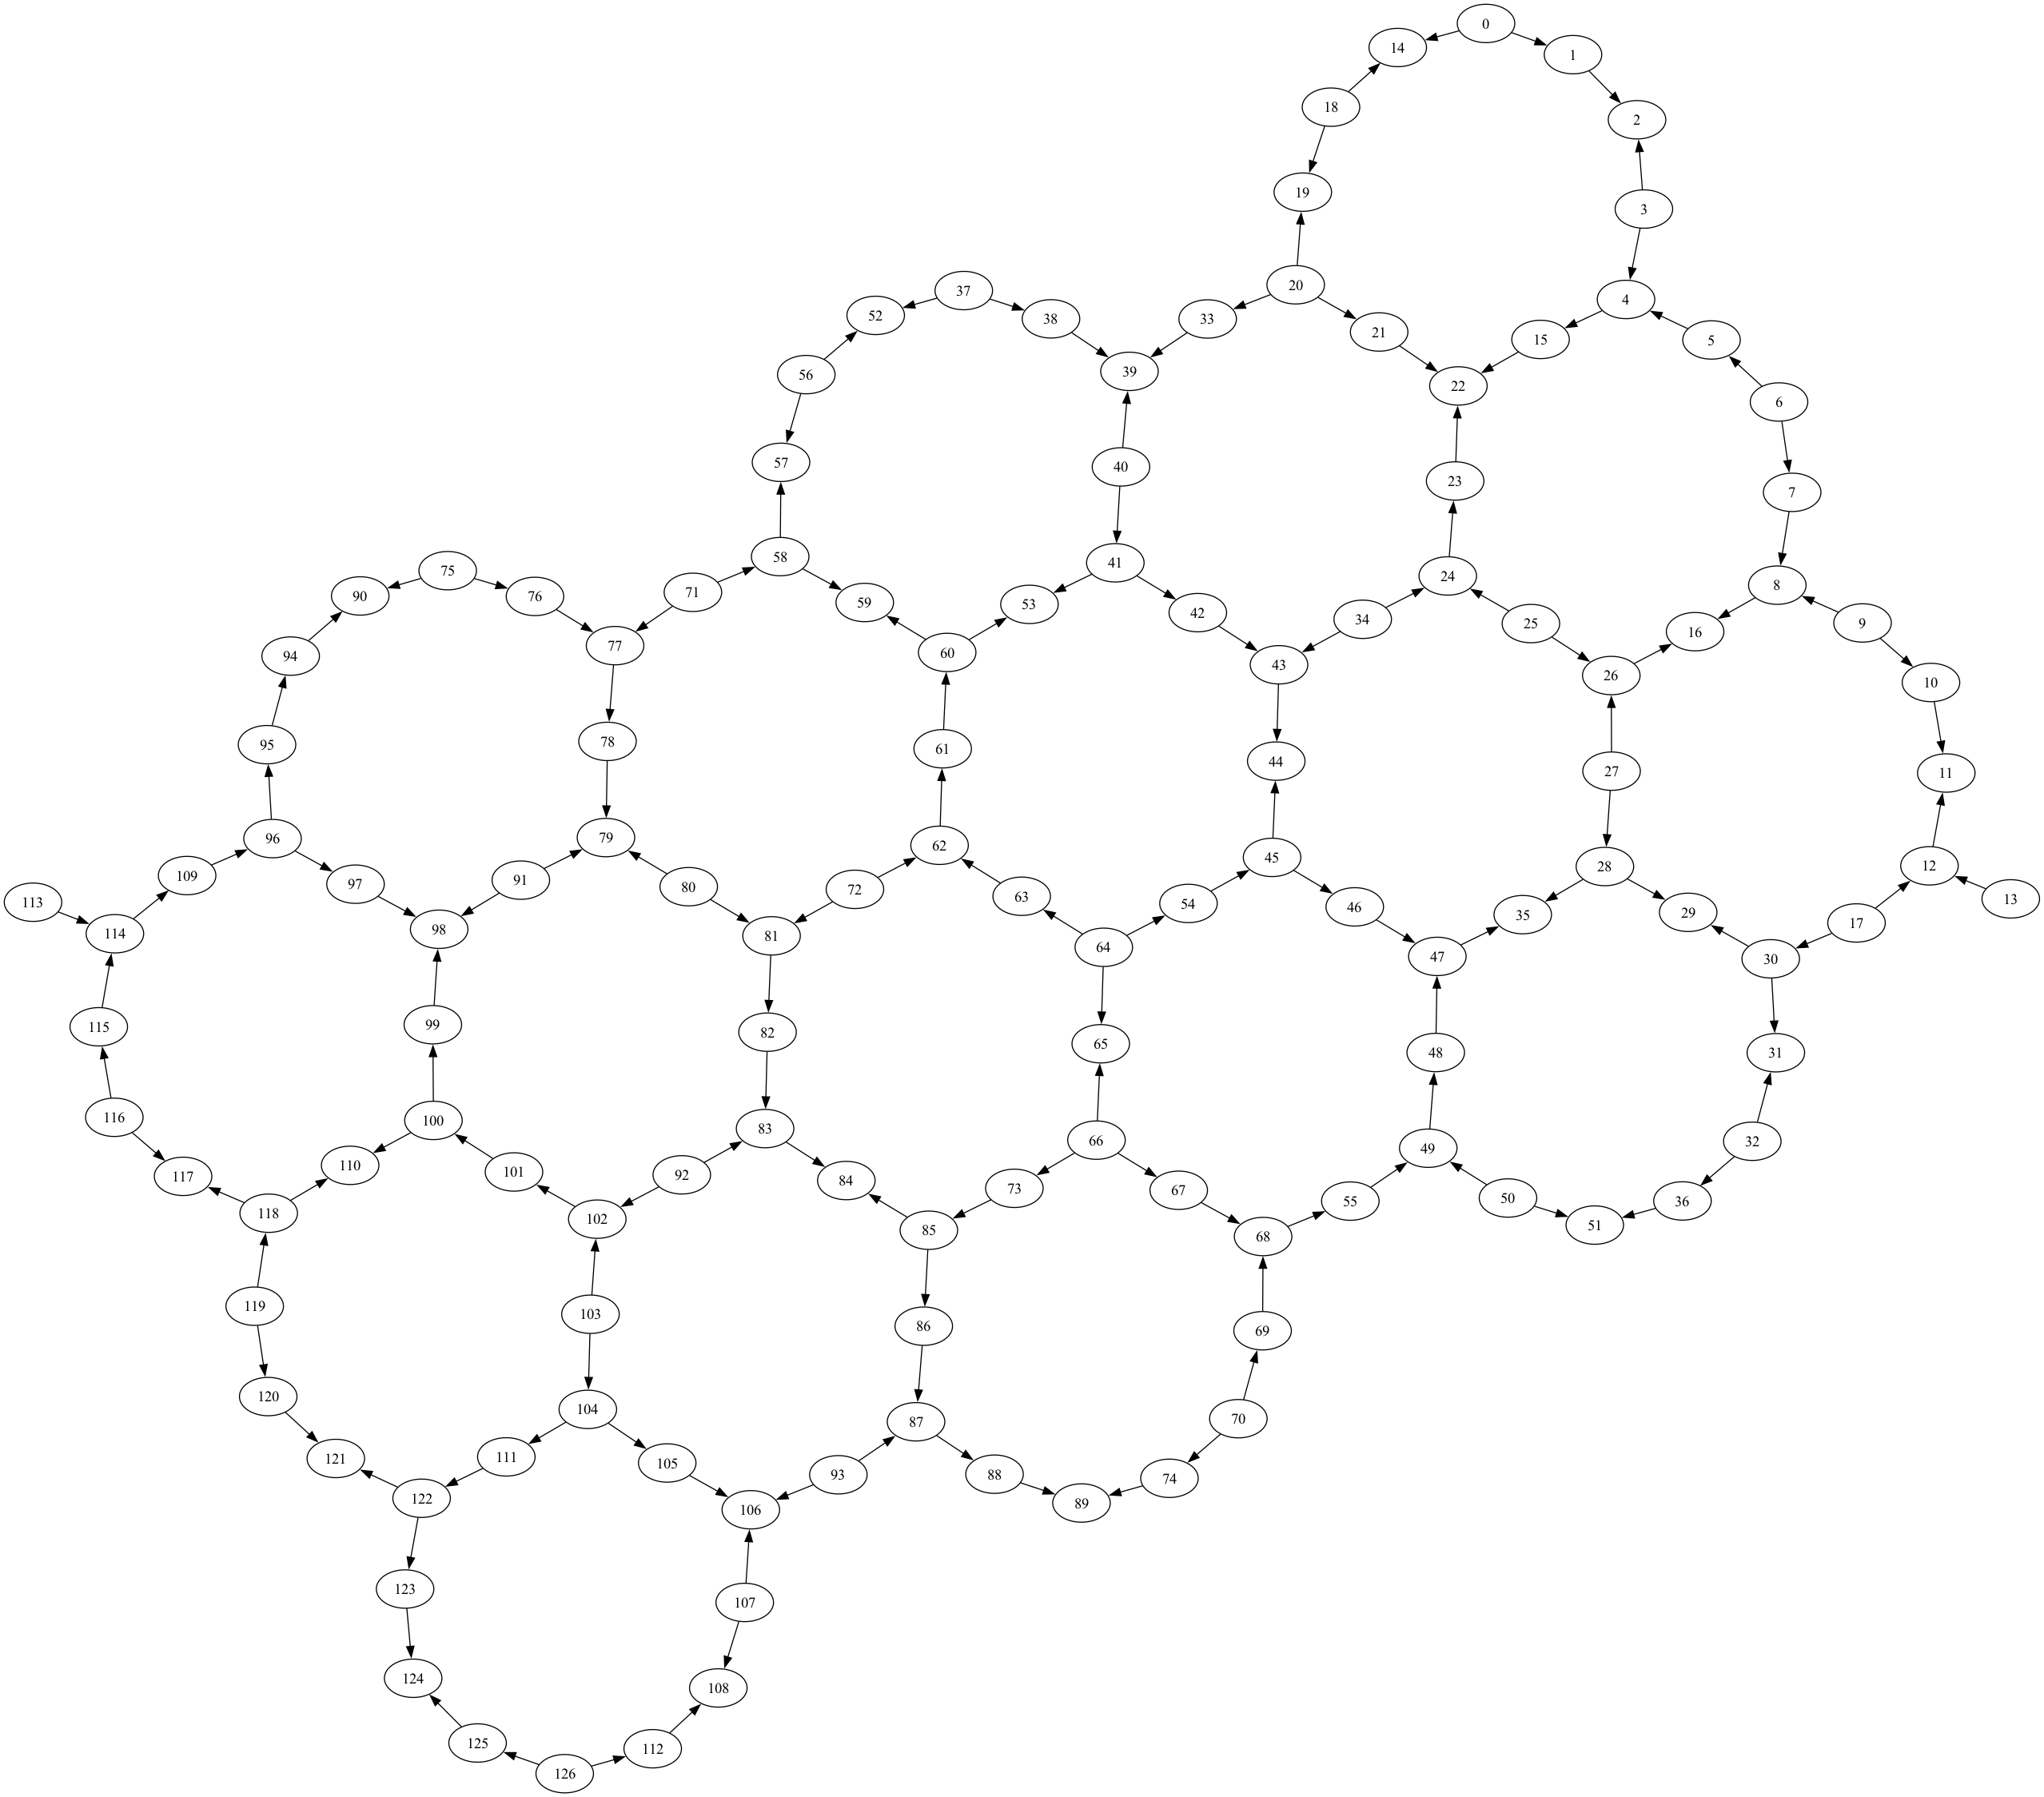

In [11]:
backend.coupling_map.draw()

In [12]:
qubit0 = 4
qubit1 = 3

In [13]:
backend.configuration().hamiltonian['vars']['jq3q4'] * GHz / 2 / np.pi

0.00209104364613846

In [14]:
backend.properties().to_dict()['qubits'][qubit0][0], backend.properties().to_dict()['qubits'][qubit0][1]

({'date': datetime.datetime(2024, 6, 26, 7, 9, 38, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 316.77866076880474},
 {'date': datetime.datetime(2024, 6, 26, 7, 23, 38, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 238.04016164531183})

In [15]:
backend.properties().to_dict()['qubits'][qubit1][0], backend.properties().to_dict()['qubits'][qubit1][1]

({'date': datetime.datetime(2024, 6, 26, 7, 9, 38, tzinfo=tzlocal()),
  'name': 'T1',
  'unit': 'us',
  'value': 134.49634062423698},
 {'date': datetime.datetime(2024, 6, 25, 17, 18, 20, tzinfo=tzlocal()),
  'name': 'T2',
  'unit': 'us',
  'value': 202.4320286958388})

In [16]:
backend.status()

## Rough calibration

In [17]:
from qiskit.circuit import Parameter
import qiskit.pulse as pulse
from qiskit_experiments.calibration_management.calibrations import Calibrations
from qiskit_experiments.library.calibration import RoughAmplitudeCal

In [18]:
def add_sched(cals, backend, gate_key, qubit, gates) -> Calibrations:
    amp = Parameter("amp")
    channel = pulse.DriveChannel(qubit)

    with qk.pulse.build(name="x", backend=backend) as x90p:
        signal = gates[gate_key]
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        param_gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "x", amp=amp
        )
        qk.pulse.play(param_gate, channel)
    print(f"Max amplitude: {np.max(np.abs(signal_samples))}")
    cals.add_schedule(x90p, (qubit,))

In [19]:
cals = Calibrations.from_backend(backend)
add_sched(cals, backend, "x1", qubit0, pico_gates)
add_sched(cals, backend, "x2", qubit1, pico_gates)

Max amplitude: 0.3012678011173944
Max amplitude: 0.30303932801317945


In [21]:
gaussian_cals = Calibrations.from_backend(backend)
add_sched(gaussian_cals, backend, "x1", qubit0, default_gates)
add_sched(gaussian_cals, backend, "x2", qubit1, default_gates)

Max amplitude: 0.09699861422442428
Max amplitude: 0.09699861422442428


In [22]:
# set some starting value for amplitude
cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x") 

gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(0.5, Parameter("amp"), (qubit1,), "x")

In [23]:
drive_amps_1 = np.linspace(-2.5, 2.5, 51)
rabi_x1 = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_1, 
    target_angle=np.pi, 
)

drive_amps_2 = np.linspace(-2.5, 2.5, 51)
rabi_x2 = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_2, 
    target_angle=np.pi, # 3 pi if working with offset
)

In [24]:
drive_amps_guass_1 = np.linspace(-5, 5, 51)
rabi_x1_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit0,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_1, 
    target_angle=np.pi, 
)

drive_amps_guass_2 = np.linspace(-5, 5, 51)
rabi_x2_gaussian = RoughAmplitudeCal(
    physical_qubits=(qubit1,), 
    calibrations=gaussian_cals, 
    backend=backend, 
    amplitudes=drive_amps_guass_2, 
    target_angle=np.pi, 
)

In [ ]:
rabi_x1_data = rabi_x1.run()
rabi_x2_data = rabi_x2.run()

In [ ]:
rabi_x1_data_gaussian = rabi_x1_gaussian.run()
rabi_x2_data_gaussian = rabi_x2_gaussian.run()

In [27]:
rabi_x1_data.job_ids, rabi_x2_data.job_ids

(['ct4mwbhezpa0008kw33g'], ['ct4mwdsmqj7g0080ccsg'])

In [28]:
rabi_x1_data_gaussian.job_ids, rabi_x2_data_gaussian.job_ids

(['ct4mwf1mqj7g0080cct0'], ['ct4mwg2mqj7g0080ccv0'])

In [43]:
rabi_x1_data.job_status(), rabi_x2_data.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [44]:
rabi_x1_data_gaussian.job_status(), rabi_x2_data_gaussian.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [47]:
rabi_x1_data = ExperimentData(experiment=rabi_x1)
rabi_x1_data.add_jobs([service.job("ct4mwbhezpa0008kw33g")])
rabi_x1.analysis.run(rabi_x1_data, replace_results=True)

rabi_x2_data = ExperimentData(experiment=rabi_x2)
rabi_x2_data.add_jobs([service.job("ct4mwdsmqj7g0080ccsg")])
rabi_x2.analysis.run(rabi_x2_data, replace_results=True)

ExperimentData(RoughAmplitudeCal, f2c20313-d15b-4613-9237-8899b17bad67, job_ids=['ct4mwdsmqj7g0080ccsg'], metadata=<9 items>)

In [48]:
rabi_x1_data_gaussian = ExperimentData(experiment=rabi_x1_gaussian)
rabi_x1_data_gaussian.add_jobs([service.job("ct4mwf1mqj7g0080cct0")])
rabi_x1_gaussian.analysis.run(rabi_x1_data_gaussian, replace_results=True)

rabi_x2_data_gaussian = ExperimentData(experiment=rabi_x2_gaussian)
rabi_x2_data_gaussian.add_jobs([service.job("ct4mwg2mqj7g0080ccv0")])
rabi_x2_gaussian.analysis.run(rabi_x2_data_gaussian, replace_results=True)

ExperimentData(RoughAmplitudeCal, dc6c15ed-129e-4e60-901a-264e7512ad93, job_ids=['ct4mwg2mqj7g0080ccv0'], metadata=<9 items>)

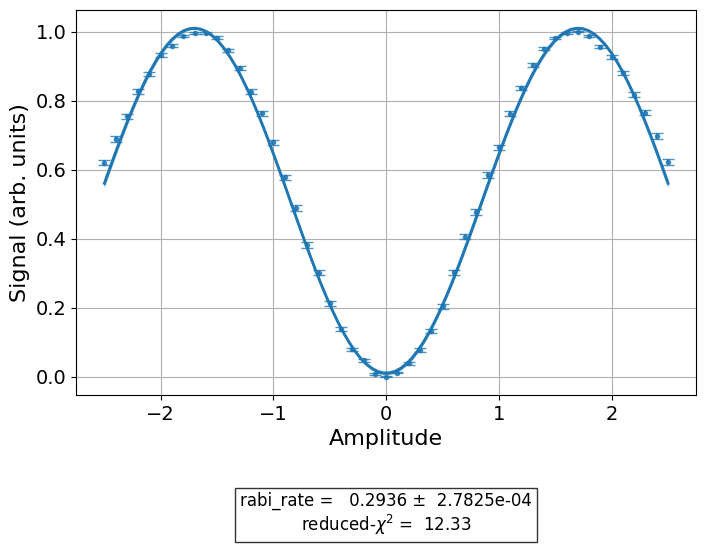

In [53]:
rabi_x1_data.block_for_results()
rabi_x1_data.figure(0)

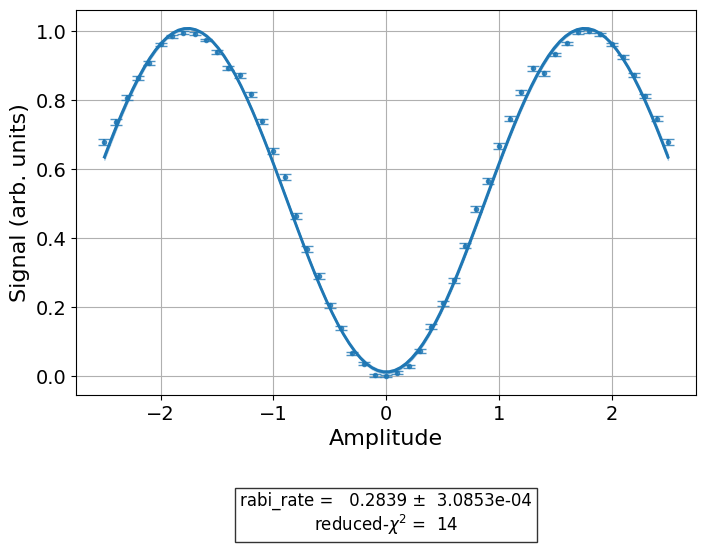

In [54]:
rabi_x2_data.block_for_results()
rabi_x2_data.figure(0)

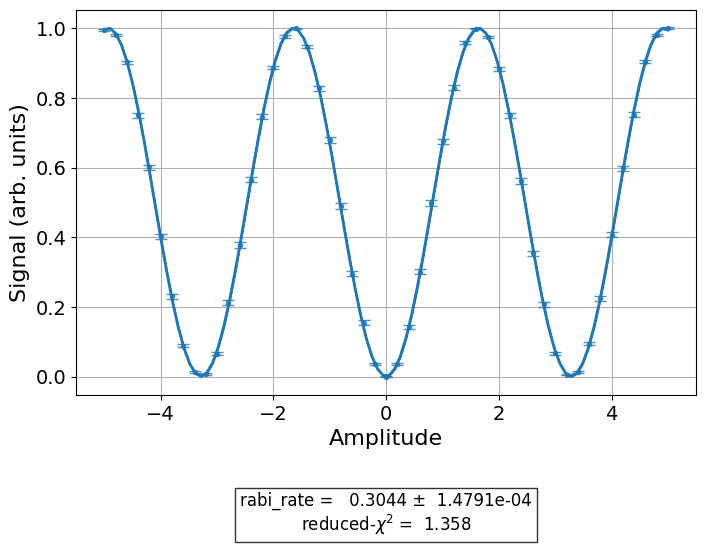

In [55]:
rabi_x1_data_gaussian.block_for_results()
rabi_x1_data_gaussian.figure(0)

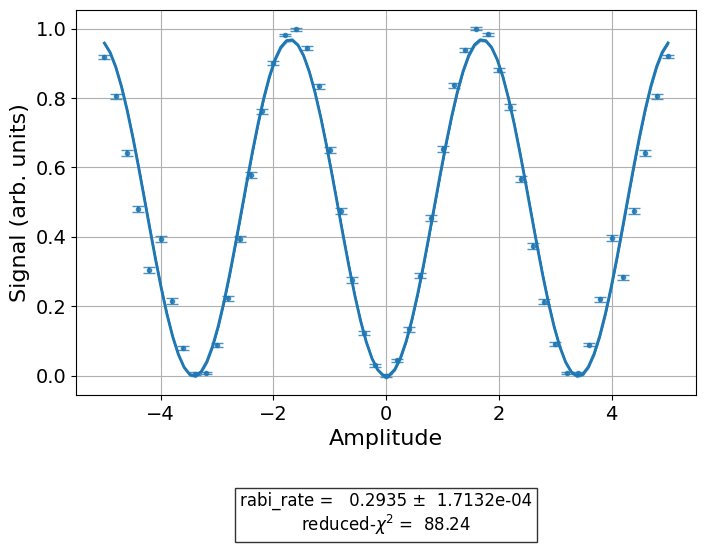

In [56]:
rabi_x2_data_gaussian.block_for_results()
rabi_x2_data_gaussian.figure(0)

In [57]:
from qiskit_experiments.calibration_management.update_library import BaseUpdater

def update_param(exp, exp_data, angle = np.pi):
    result_index = exp.experiment_options.result_index
    rate = 2 * np.pi * BaseUpdater.get_value(exp_data, exp.__outcome__, result_index)

    # angle, _, _, prev_amp = exp_data.metadata["angles_schedules"][0]
    value = np.round(angle / rate, decimals=8)
    print(f"Target angle: {angle}")
    print(f"New amplitude: {value}")
    return value

In [61]:
rough_x1_amp = update_param(rabi_x1, rabi_x1_data)
rough_x2_amp = update_param(rabi_x2, rabi_x2_data)

Target angle: 3.141592653589793
New amplitude: 1.70310019
Target angle: 3.141592653589793
New amplitude: 1.76137741


In [60]:
rough_x1_amp_gaussian = update_param(rabi_x1_gaussian, rabi_x1_data_gaussian)
rough_x2_amp_gaussian = update_param(rabi_x2_gaussian, rabi_x2_data_gaussian)

Target angle: 3.141592653589793
New amplitude: 1.64252038
Target angle: 3.141592653589793
New amplitude: 1.70369229


In [62]:
cals.add_parameter_value(rough_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(rough_x2_amp, Parameter("amp"), (qubit1,), "x")

In [63]:
gaussian_cals.add_parameter_value(rough_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(rough_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

In [64]:
rough_x1 = cals.get_schedule("x", (qubit0,))
rough_x2 = cals.get_schedule("x", (qubit1,))
rough_x1, rough_x2

(ScheduleBlock(Play(x(duration=120, amp=1.70310019, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.76137741, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [65]:
rough_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
rough_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
rough_x1_gaussian, rough_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.64252038, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.70369229, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [66]:
np.trapz(rough_x1.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((-5.343539050801943+0j), (5.52738178596271+0j))

In [67]:
np.trapz(rough_x1_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2_gaussian.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((5.16011059868843+0j), (5.352287100713333+0j))

## Fine calibration 

In [68]:
current_x1 = cals.get_schedule("x", (qubit0,))
current_x2 = cals.get_schedule("x", (qubit1,))
current_x1, current_x2

(ScheduleBlock(Play(x(duration=120, amp=1.70310019, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.76137741, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [69]:
current_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
current_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
current_x1_gaussian, current_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.64252038, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.70369229, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [70]:
def get_fine_circuit(length: int, qubit: int, num_qubits: int, schedule):
    qc = qk.QuantumCircuit(num_qubits, 1)
    qc.sx(qubit)
    for _ in range(length):
        qc.x(qubit)
    qc.measure(qubit, 0)

    x_gate = qk.circuit.library.XGate()
    qc.add_calibration(x_gate, (qubit,), schedule)

    return qc

In [71]:
num_qubits = backend.num_qubits

In [72]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")
sampler = Sampler(backend=backend, session=session)

Session id: ct4rw107srd00088s7s0


In [73]:
lengths = range(0, 20)

In [74]:
x1_testing = [get_fine_circuit(l, qubit0, num_qubits, current_x1) for l in lengths]
x2_testing = [get_fine_circuit(l, qubit1, num_qubits, current_x2) for l in lengths]

In [75]:
x1_testing_gaussian = [get_fine_circuit(l, qubit0, num_qubits, current_x1_gaussian) for l in lengths]
x2_testing_gaussian = [get_fine_circuit(l, qubit1, num_qubits, current_x2_gaussian) for l in lengths]

In [76]:
x1_testing_job = sampler.run(x1_testing, shots=1024)
x2_testing_job = sampler.run(x2_testing, shots=1024)

In [77]:
x1_testing_job_gaussian = sampler.run(x1_testing_gaussian, shots=1024)
x2_testing_job_gaussian = sampler.run(x2_testing_gaussian, shots=1024)

In [78]:
x1_testing_job.job_id(), x2_testing_job.job_id()

('ct4rw1r7srd00088s7t0', 'ct4rw28mqj7g0080cw3g')

In [79]:
x1_testing_job_gaussian.job_id(), x2_testing_job_gaussian.job_id()

('ct4rw2rezpa0008kwgag', 'ct4rw382tw9g008m35pg')

In [112]:
x1_testing_job.status(), x2_testing_job.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [113]:
x1_testing_job_gaussian.status(), x2_testing_job_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [114]:
x1_testing_job = service.job("ct4rw1r7srd00088s7t0")
x2_testing_job = service.job("ct4rw28mqj7g0080cw3g")

In [115]:
x1_testing_job_gaussian = service.job("ct4rw2rezpa0008kwgag")
x2_testing_job_gaussian = service.job("ct4rw382tw9g008m35pg")

In [116]:
x1_results = x1_testing_job.result()
x1_counts = []
for result in x1_results:
    x1_counts.append(result.data.c.get_counts()['1'] / 1024)

x2_results = x2_testing_job.result()
x2_counts = []
for result in x2_results:
    x2_counts.append(result.data.c.get_counts()['1'] / 1024)

In [117]:
x1_results_gaussian = x1_testing_job_gaussian.result()
x1_counts_gaussian = []
for result in x1_results_gaussian:
    x1_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

x2_results_gaussian = x2_testing_job_gaussian.result()
x2_counts_gaussian = []
for result in x2_results_gaussian:
    x2_counts_gaussian.append(result.data.c.get_counts()['1'] / 1024)

In [118]:
def get_d_theta(counts, estimate=0.1, plot=True):
    def fit_function(x_values, y_values, function, init_params):
        fitparams, conv = curve_fit(function, x_values, y_values, init_params)
        y_fit = function(x_values, *fitparams)
        return fitparams, y_fit, conv

    starting_params = [estimate]
    fit_params, y_fit, _ = fit_function(
        lengths,
        counts,
        lambda x, d_theta: (
            (1 / 2) * np.cos((d_theta + np.pi) * x - (np.pi / 2)) + 0.5
        ),
        starting_params,
    )

    if plot:
        fine_fit = [(1 / 2) * np.cos((fit_params[0] + np.pi) * x - (np.pi / 2)) + 0.5 for x in np.linspace(0, lengths[-1], 200)]
        plt.scatter(lengths, counts, marker="x", color="black")
        plt.plot(np.linspace(0, lengths[-1], 200), fine_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1")
        plt.title("Fine amplitude calibration")
        plt.show()

    d_theta = fit_params[0]  # get over/under rotation
    return d_theta

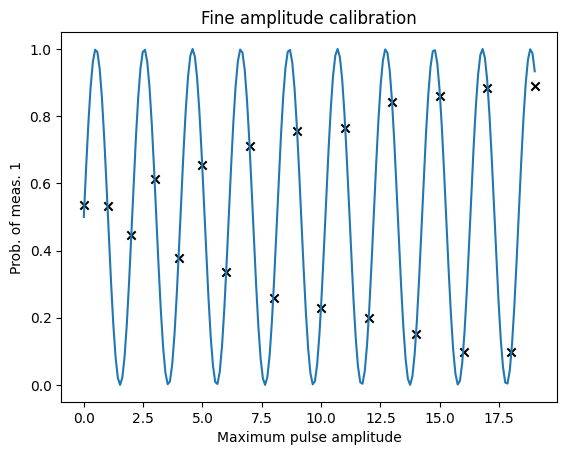

In [119]:
d_theta_x1 = get_d_theta(x1_counts, 0.1)

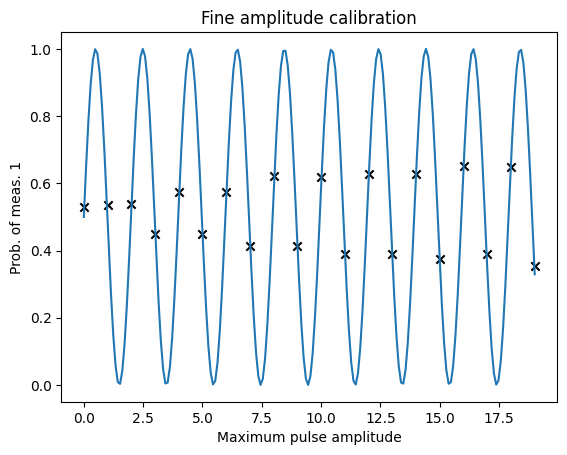

In [120]:
d_theta_x2 = get_d_theta(x2_counts, 0.1)

In [121]:
scale_x1 = (np.pi) / (np.pi + d_theta_x1)
scale_x2 = (np.pi) / (np.pi + d_theta_x2)
scale_x1, scale_x2

(1.0178828936501425, 0.9941957726247209)

In [122]:
fine_x1_amp = rough_x1_amp * scale_x1
fine_x2_amp = rough_x2_amp * scale_x2
fine_x1_amp, fine_x2_amp

(1.7335565495733074, 1.7511539750186798)

In [123]:
cals.add_parameter_value(fine_x1_amp, Parameter("amp"), (qubit0,), "x")
cals.add_parameter_value(fine_x2_amp, Parameter("amp"), (qubit1,), "x")

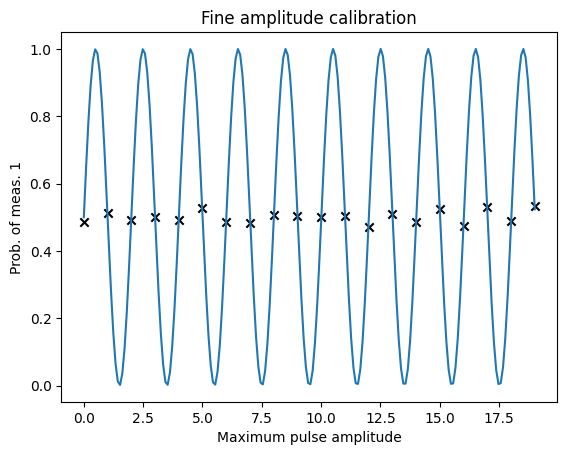

In [124]:
d_theta_x1_gaussian = get_d_theta(x1_counts_gaussian, 0.1)

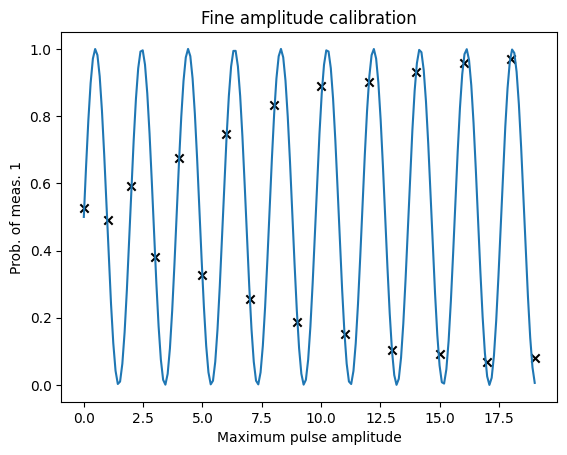

In [125]:
d_theta_x2_gaussian = get_d_theta(x2_counts_gaussian, 0.1)

In [126]:
scale_x1_gaussian = (np.pi) / (np.pi + d_theta_x1_gaussian)
scale_x2_gaussian = (np.pi) / (np.pi + d_theta_x2_gaussian)
scale_x1_gaussian, scale_x2_gaussian

(1.0007880694390818, 0.9768496495389803)

In [127]:
fine_x1_amp_gaussian = rough_x1_amp_gaussian * scale_x1_gaussian
fine_x2_amp_gaussian = rough_x2_amp_gaussian * scale_x2_gaussian
fine_x1_amp_gaussian, fine_x2_amp_gaussian

(1.643814800114547, 1.6642512164087628)

In [128]:
gaussian_cals.add_parameter_value(fine_x1_amp_gaussian, Parameter("amp"), (qubit0,), "x")
gaussian_cals.add_parameter_value(fine_x2_amp_gaussian, Parameter("amp"), (qubit1,), "x")

## Dynamical decoupling sequences

In [129]:
final_x1 = cals.get_schedule("x", (qubit0,))
final_x2 = cals.get_schedule("x", (qubit1,))
final_x1, final_x2

(ScheduleBlock(Play(x(duration=120, amp=1.7335565496, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.751153975, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [130]:
final_x1_gaussian = gaussian_cals.get_schedule("x", (qubit0,))
final_x2_gaussian = gaussian_cals.get_schedule("x", (qubit1,))
final_x1_gaussian, final_x2_gaussian

(ScheduleBlock(Play(x(duration=120, amp=1.6438148001, angle=0), DriveChannel(4)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=120, amp=1.6642512164, angle=0), DriveChannel(3)), name="x", transform=AlignLeft()))

In [131]:
def xyxy_sequence(repetitions: int, num_qubits: int, q0: int, q1: int, schedules = None):
    qc = qk.QuantumCircuit(num_qubits, 2)
    qc.sx(q0)
    qc.sx(q1)
    for _ in range(repetitions):
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)
        qc.x(q0)
        qc.rz(np.pi, q0)
        qc.x(q0)

        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
        qc.x(q1)
        qc.rz(np.pi, q1)
        qc.x(q1)
    qc.sx(q0)
    qc.sx(q1)
    qc.measure(q0, 0)
    qc.measure(q1, 1)

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])

    return qc

In [132]:
num_qubits = backend.num_qubits
num_qubits

127

In [133]:
example = xyxy_sequence(1, num_qubits, qubit0, qubit1)
example.draw(idle_wires=False)

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐   ┌─┐
q_3: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├───┤M├
     ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤┌─┐└╥┘
q_4: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├┤M├─╫─
     └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘└╥┘ ║ 
c: 2/═══════════════════════════════════════════════════╩══╩═
                                                        0  1

In [359]:
lengths = list(range(0, 401, 4))

In [135]:
dd_circuits_robust = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1, final_x2]) for i in lengths]
dd_circuits_gaussian = [xyxy_sequence(i, num_qubits, qubit0, qubit1, [final_x1_gaussian, final_x2_gaussian]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, num_qubits, qubit0, qubit1) for i in lengths]

In [136]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_gaussian = sampler.run(dd_circuits_gaussian, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [141]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id(), dd_jobs_gaussian.job_id()

('ct4vx3wkmkz00086hbmg', 'ct4vx6w2tw9g008m43bg', 'ct4vx642tw9g008m43a0')

In [147]:
dd_jobs_robust.status(), dd_jobs_default.status(), dd_jobs_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [148]:
dd_jobs_robust = service.job("ct4vx3wkmkz00086hbmg")
dd_jobs_default = service.job("ct4vx6w2tw9g008m43bg")
dd_jobs_gaussian = service.job("ct4vx642tw9g008m43a0")

In [149]:
robust_results = dd_jobs_robust.result()
robust_counts = []
robust_counts_q0 = []
robust_counts_q1 = []
for result in robust_results:
    robust_counts.append(result.data.c.get_counts())
    robust_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    robust_counts_q1.append(result.data.c.slice_bits(1).get_counts())

default_results = dd_jobs_default.result()
default_counts = []
default_counts_q0 = []
default_counts_q1 = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())
    default_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    default_counts_q1.append(result.data.c.slice_bits(1).get_counts())


gaussian_results = dd_jobs_gaussian.result()
gaussian_counts = []
gaussian_counts_q0 = []
gaussian_counts_q1 = []
for result in gaussian_results:
    gaussian_counts.append(result.data.c.get_counts())
    gaussian_counts_q0.append(result.data.c.slice_bits(0).get_counts())
    gaussian_counts_q1.append(result.data.c.slice_bits(1).get_counts())

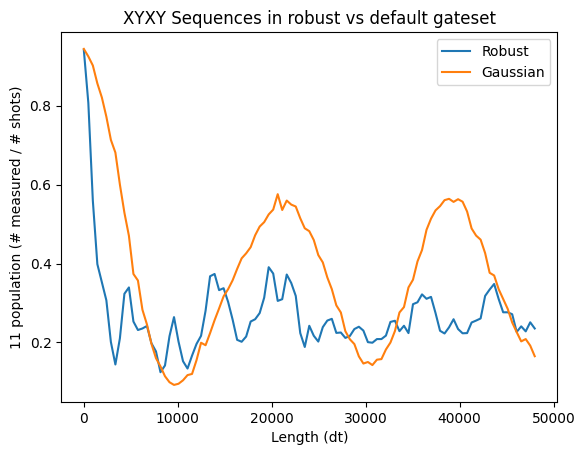

In [370]:
robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
default_11 = [count.get("11", 0) / 2048 for count in default_counts]
gaussian_11 = [count.get("11", 0) / 2048 for count in gaussian_counts]

plt.plot([l * duration for l in lengths], robust_11, label="Robust")
# plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.plot([l * duration for l in lengths], gaussian_11, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel("11 population (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

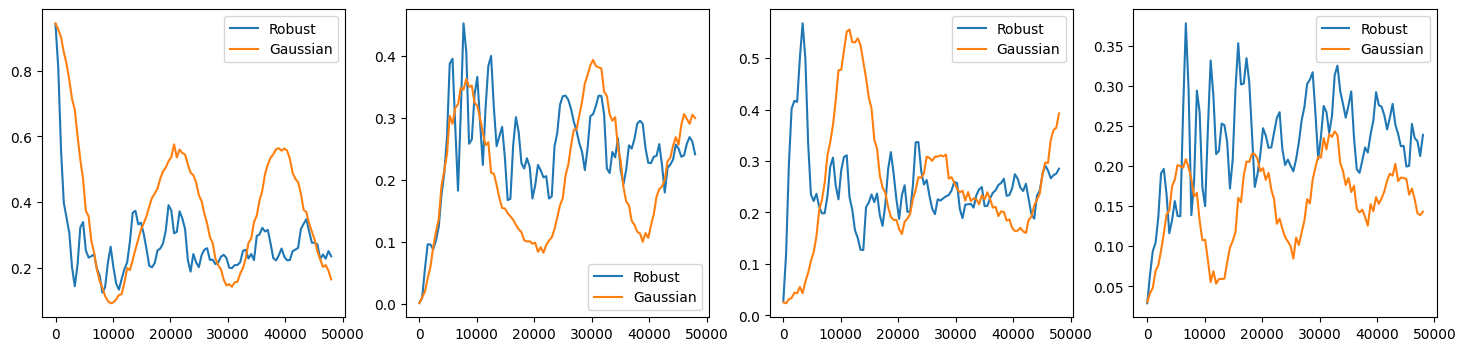

In [373]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
gaussian_11 = [count.get("11", 0) / 2048 for count in gaussian_counts]

axes[0].plot([l * duration for l in lengths], robust_11, label="Robust")
axes[0].plot([l * duration for l in lengths], gaussian_11, label="Gaussian")
axes[0].legend()

robust_00 = [count.get("00", 0) / 2048 for count in robust_counts]
gaussian_00 = [count.get("00", 0) / 2048 for count in gaussian_counts]

axes[1].plot([l * duration for l in lengths], robust_00, label="Robust")
axes[1].plot([l * duration for l in lengths], gaussian_00, label="Gaussian")
axes[1].legend()

robust_10 = [count.get("10", 0) / 2048 for count in robust_counts]
gaussian_10 = [count.get("10", 0) / 2048 for count in gaussian_counts]

axes[2].plot([l * duration for l in lengths], robust_10, label="Robust")
axes[2].plot([l * duration for l in lengths], gaussian_10, label="Gaussian")
axes[2].legend()

robust_01 = [count.get("01", 0) / 2048 for count in robust_counts]
gaussian_01 = [count.get("01", 0) / 2048 for count in gaussian_counts]

axes[3].plot([l * duration for l in lengths], robust_01, label="Robust")
axes[3].plot([l * duration for l in lengths], gaussian_01, label="Gaussian")
axes[3].legend()

plt.show()

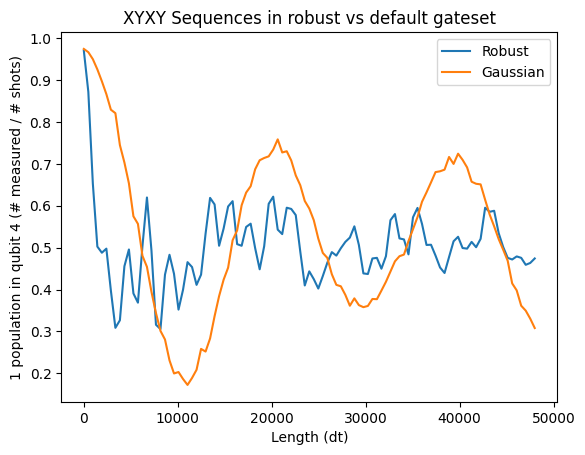

In [159]:
robust_1 = [count.get("1", 0) / 2048 for count in robust_counts_q0]
default_1 = [count.get("1", 0)  / 2048 for count in default_counts_q0]
gaussian_1 = [count.get("1", 0)  / 2048 for count in gaussian_counts_q0]

plt.plot([l * duration for l in lengths], robust_1, label="Robust")
# plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * duration for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit0} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

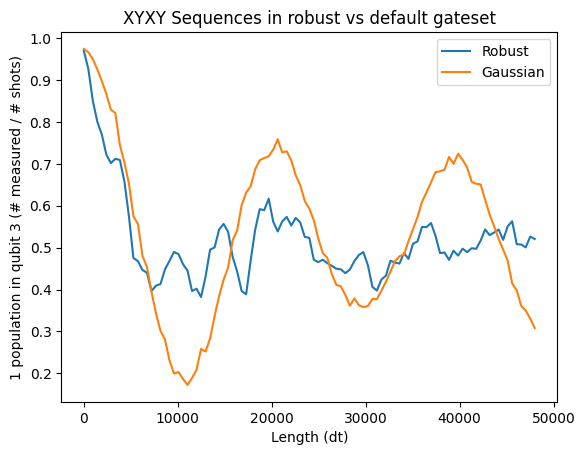

In [160]:
robust_1= [count.get("1", 0) / 2048 for count in robust_counts_q1]
default_1 = [count.get("1", 0)  / 2048 for count in default_counts_q1]

plt.plot([l * duration for l in lengths], robust_1, label="Robust")
# plt.plot([l * 120 for l in lengths], default_1, label="Default")
plt.plot([l * duration for l in lengths], gaussian_1, label="Gaussian")
plt.xlabel("Length (dt)")
plt.ylabel(f"1 population in qubit {qubit1} (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

## Randomized benchmarking
We also want to verify our robust gates have good fidelity compared to the Guassian gates.

In [176]:
def set_backend_calibrations(backend, qubit0: int, qubit1: int, schedules):
    """
    Schedules are expected to be in the order:
    - (x, qubit0)
    - (x, qubit1)
    - (sx, qubit0)
    - (sx, qubit1)

    https://github.com/Qiskit-Extensions/qiskit-experiments/issues/1032
    """
    for i, qubit in enumerate([qubit0, qubit1]):
        backend.target["x"][(qubit,)].calibration = schedules[i]
        backend.target.update_instruction_properties("x", (qubit,), qk.transpiler.InstructionProperties(calibration=schedules[i]))

        # backend.target["sx"][(qubit,)].calibration = schedules[i + 2]
        # backend.target.update_instruction_properties("sx", (qubit,), qk.transpiler.InstructionProperties(calibration=schedules[i + 2]))
    return backend

In [177]:
robust_backend = service.get_backend("ibm_nazca")
gaussian_backend = service.get_backend("ibm_nazca")

In [178]:
robust_backend = set_backend_calibrations(robust_backend, qubit0, qubit1, [final_x1, final_x2])
gaussian_backend = set_backend_calibrations(gaussian_backend, qubit0, qubit1, [final_x1_gaussian, final_x2_gaussian])

In [179]:
lengths_2_qubit = np.arange(1, 200, 30)
lengths_1_qubit = np.arange(1, 800, 200)
num_samples = 10
seed = 1010
qubits = (qubit0, qubit1)

# Run a 1-qubit RB experiment on qubits 1, 2 to determine the error-per-gate of 1-qubit gates
single_exps = BatchExperiment(
    [
        StandardRB((qubit,), lengths_1_qubit, num_samples=num_samples, seed=seed)
        for qubit in qubits
    ]
)

expdata_1q_robust = single_exps.run(robust_backend)
expdata_1q_gaussian = single_exps.run(gaussian_backend)

In [195]:
expdata_1q_robust.job_ids, expdata_1q_gaussian.job_ids

(['ct4x7kp2tw9g008m4sn0'], ['ct4x7ne7srd00088twzg'])

In [223]:
expdata_1q_robust.status(), expdata_1q_gaussian.status()

(<ExperimentStatus.DONE: 'experiment jobs and analysis have successfully run'>,
 <ExperimentStatus.DONE: 'experiment jobs and analysis have successfully run'>)

Robust qubit 4


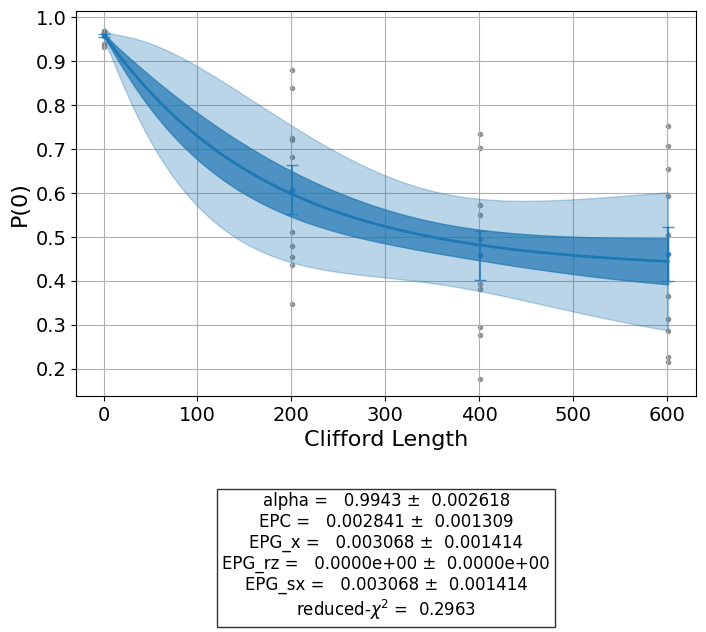

In [257]:
print(f"Robust qubit {qubit0}")
expdata_1q_robust.child_data()[0].figure(0)

Robust qubit 3


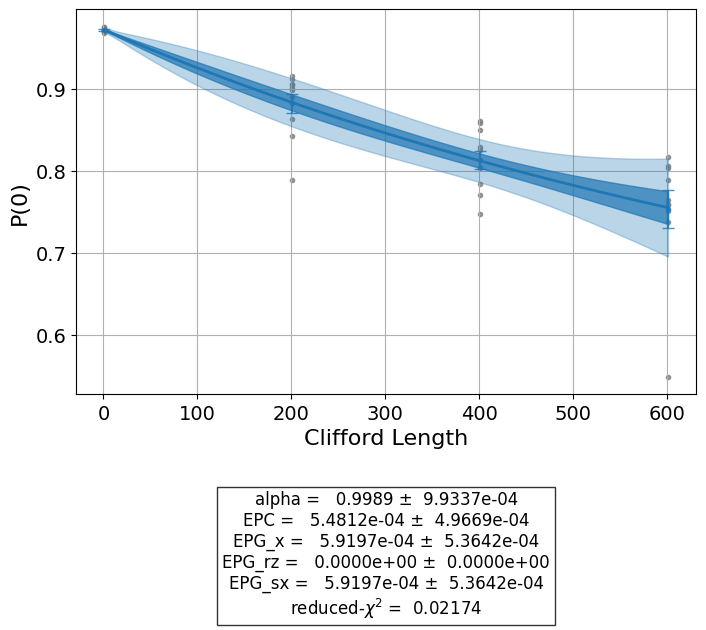

In [258]:
print(f"Robust qubit {qubit1}")
expdata_1q_robust.child_data()[1].figure(0)

Gaussian qubit 4


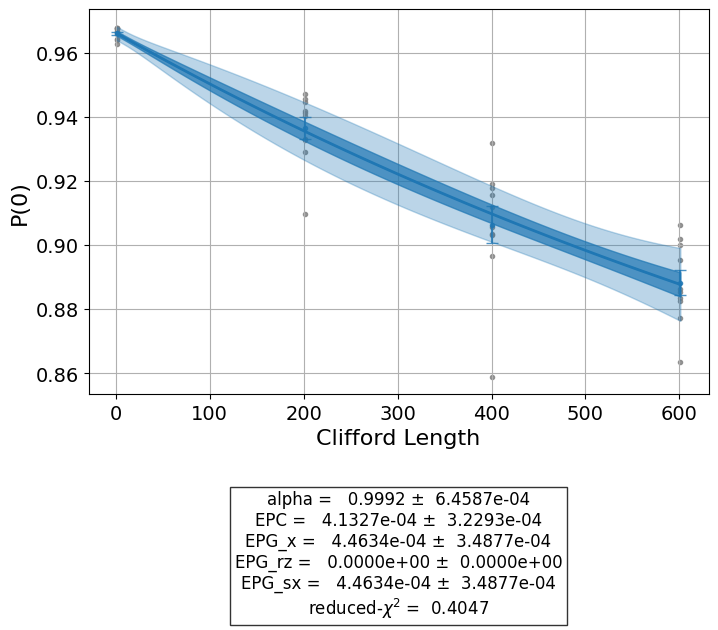

In [259]:
print(f"Gaussian qubit {qubit0}")
expdata_1q_gaussian.child_data()[0].figure(0)

Gaussian qubit 3


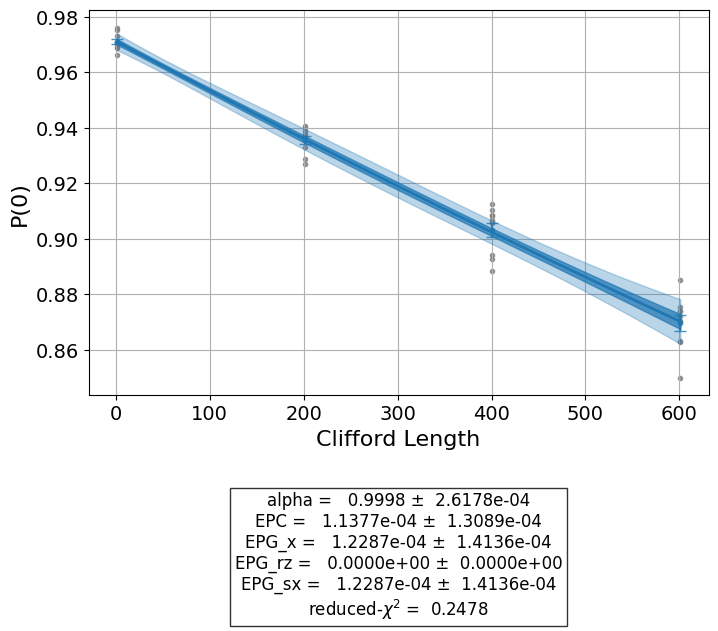

In [269]:
print(f"Gaussian qubit {qubit1}")
expdata_1q_gaussian.child_data()[1].figure(0)

In [376]:
exp_2q_robust = StandardRB(qubits, lengths_2_qubit, num_samples=num_samples, seed=seed)
exp_2q_robust.analysis.set_options(
    epg_1_qubit=None,
    gate_error_ratio=None,
)
exp_2q_gaussian = StandardRB(qubits, lengths_2_qubit, num_samples=num_samples, seed=seed)
exp_2q_gaussian.analysis.set_options(
    epg_1_qubit=None,
    gate_error_ratio=None,
)

In [ ]:
expdata_2q_robust = exp_2q_robust.run(robust_backend)
expdata_2q_gaussian = exp_2q_gaussian.run(gaussian_backend)

In [355]:
expdata_2q_robust.job_ids, expdata_2q_gaussian.job_ids

(['ct4z6g22tw9g008m5eg0'], ['ct4z6mtmqj7g0080f6hg'])

In [378]:
expdata_2q_robust.job_status(), expdata_2q_gaussian.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

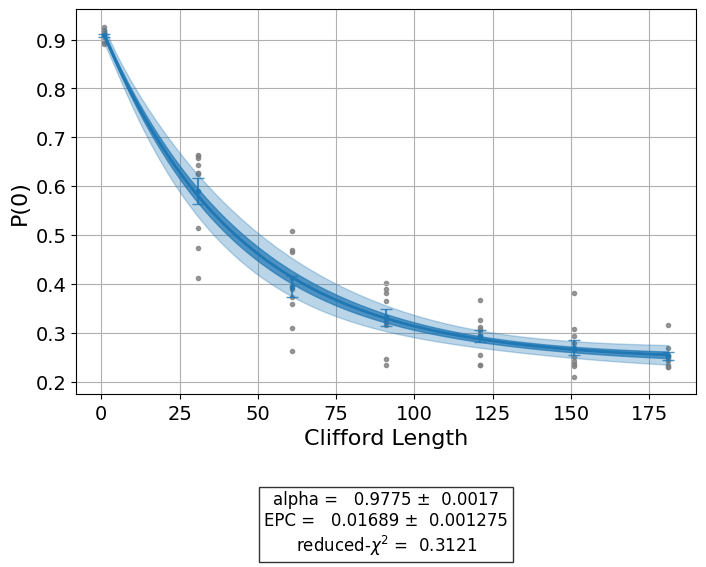

In [333]:
expdata_2q_robust.figure(0)

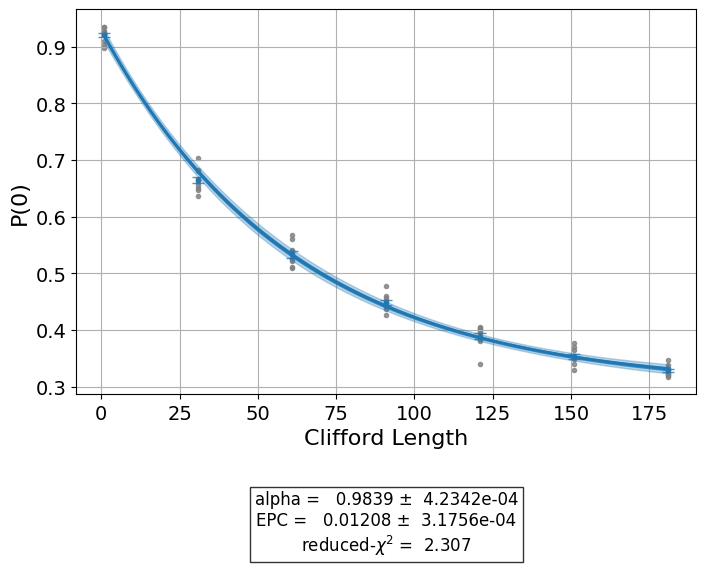

In [335]:
expdata_2q_gaussian.figure(0)